# Notebook 05 - Core Model Comparison

Scope: compare Logistic Regression, Random Forest, and XGBoost using existing CSV outputs from `churn_pipeline_v2/reports/data_reports/` only. This notebook does not train models, refit preprocessing, tune thresholds, generate probabilities, or load legacy artifacts.

## 1. Imports

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

MODEL_ORDER = ['Logistic Regression', 'Random Forest', 'XGBoost']
METRIC_COLUMNS = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'PR_AUC']
RECALL_TARGET = 0.85
plt.rcParams['figure.dpi'] = 120

## 2. Path Setup

In [2]:
def find_refactor_root(start_path: Path) -> Path:
    current = start_path.resolve()
    for candidate in [current, *current.parents]:
        if candidate.name == 'churn_pipeline_v2':
            return candidate
        nested = candidate / 'churn_pipeline_v2'
        if nested.exists() and nested.is_dir():
            return nested.resolve()
    raise FileNotFoundError('Could not locate churn_pipeline_v2 from the current working directory.')


CURRENT_WORKING_DIRECTORY = Path.cwd().resolve()
REFACTOR_ROOT = find_refactor_root(CURRENT_WORKING_DIRECTORY)
REPO_ROOT = REFACTOR_ROOT.parent
TARGET_NOTEBOOK_PATH = REFACTOR_ROOT / 'notebooks' / '05_Model_Comparison.ipynb'
LEGACY_NOTEBOOK_PATH = REPO_ROOT / 'notebooks' / '05_Model_Visualization.ipynb'

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from churn_pipeline_v2.src.path import DATA_REPORTS_DIR, FIGURES_DIR

DATA_REPORTS_DIR = Path(DATA_REPORTS_DIR)
FIGURES_DIR = Path(FIGURES_DIR)

path_checks = pd.DataFrame([
    {'Name': 'Current working directory', 'Path': CURRENT_WORKING_DIRECTORY, 'Exists': CURRENT_WORKING_DIRECTORY.exists()},
    {'Name': 'Refactor root', 'Path': REFACTOR_ROOT, 'Exists': REFACTOR_ROOT.exists()},
    {'Name': 'Target notebook', 'Path': TARGET_NOTEBOOK_PATH, 'Exists': TARGET_NOTEBOOK_PATH.exists()},
    {'Name': 'Legacy visualization notebook', 'Path': LEGACY_NOTEBOOK_PATH, 'Exists': LEGACY_NOTEBOOK_PATH.exists()},
    {'Name': 'Data reports folder', 'Path': DATA_REPORTS_DIR, 'Exists': DATA_REPORTS_DIR.exists()},
    {'Name': 'Figures folder', 'Path': FIGURES_DIR, 'Exists': FIGURES_DIR.exists()},
])
display(path_checks)
if not DATA_REPORTS_DIR.exists() or not FIGURES_DIR.exists():
    raise FileNotFoundError('Required refactor output folders are missing.')

,Name,Path,Exists
0,Current working directory,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
1,Refactor root,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
2,Target notebook,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
3,Legacy visualization notebook,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
4,Data reports folder,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
5,Figures folder,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True


## 3. Helper Functions

In [3]:
COLUMN_VARIANTS = {
    'Model': ['Model', 'model'],
    'Dataset': ['Dataset', 'dataset', 'Split', 'split'],
    'Threshold': ['Threshold', 'threshold', 'Selected Threshold', 'Selected_Threshold', 'selected_threshold'],
    'Accuracy': ['Accuracy', 'accuracy'],
    'Precision': ['Precision', 'precision'],
    'Recall': ['Recall', 'recall'],
    'F1': ['F1', 'F1-score', 'F1_Score', 'f1', 'f1_score'],
    'ROC_AUC': ['ROC-AUC', 'ROC_AUC', 'roc_auc'],
    'PR_AUC': ['PR-AUC', 'PR_AUC', 'pr_auc'],
    'TP': ['TP', 'tp'],
    'FP': ['FP', 'fp'],
    'TN': ['TN', 'tn'],
    'FN': ['FN', 'fn'],
    'FPR': ['FPR', 'False Positive Rate', 'False_Positive_Rate', 'false_positive_rate'],
    'FNR': ['FNR', 'False Negative Rate', 'False_Negative_Rate', 'false_negative_rate'],
    'Meets_Recall_Target': ['Meets Recall Target', 'Meets_Recall_Target', 'Meets Recall >= 0.85', 'meets_recall_target'],
}


NORMALIZED_COLUMNS = [
    'Model', 'Dataset', 'Evaluation_Type', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1',
    'ROC_AUC', 'PR_AUC', 'TP', 'FP', 'TN', 'FN', 'FPR', 'FNR', 'Meets_Recall_Target'
]


def find_existing_file(candidates: list[str]) -> Path:
    for filename in candidates:
        path = DATA_REPORTS_DIR / filename
        if path.exists():
            return path
    raise FileNotFoundError(f'None of these files exist: {candidates}')


def first_existing_column(df: pd.DataFrame, variants: list[str]) -> str | None:
    for column in variants:
        if column in df.columns:
            return column
    return None


def normalize_metrics(df: pd.DataFrame, model_name: str, dataset: str, evaluation_type: str) -> pd.DataFrame:
    normalized = pd.DataFrame(index=df.index)
    for normalized_name, variants in COLUMN_VARIANTS.items():
        source_column = first_existing_column(df, variants)
        normalized[normalized_name] = df[source_column] if source_column else np.nan

    normalized['Model'] = normalized['Model'].fillna(model_name)
    normalized['Dataset'] = normalized['Dataset'].fillna(dataset).astype(str).str.lower()
    normalized['Evaluation_Type'] = evaluation_type
    normalized['Meets_Recall_Target'] = normalized['Meets_Recall_Target'].fillna(normalized['Recall'] >= RECALL_TARGET)

    for column in ['Threshold', *METRIC_COLUMNS, 'TP', 'FP', 'TN', 'FN', 'FPR', 'FNR']:
        normalized[column] = pd.to_numeric(normalized[column], errors='coerce')
    normalized['Model'] = pd.Categorical(normalized['Model'], categories=MODEL_ORDER, ordered=True)
    return normalized[NORMALIZED_COLUMNS].sort_values('Model').reset_index(drop=True)


def display_and_save_table(df: pd.DataFrame, filename: str, title: str) -> Path:
    path = DATA_REPORTS_DIR / filename
    df.to_csv(path, index=False)
    print(title)
    display(df)
    print(f'Table shape: {df.shape}')
    print(f'Saved table: {path}')
    return path


def save_current_figure(filename: str) -> Path:
    path = FIGURES_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches='tight')
    print(f'Saved figure: {path}')
    display(plt.gcf())
    plt.close()
    return path


def assert_three_models(df: pd.DataFrame, table_name: str) -> None:
    models = df['Model'].astype(str).tolist()
    if models != MODEL_ORDER:
        raise ValueError(f'{table_name} must contain models in order {MODEL_ORDER}, got {models}')
    if len(df) != 3:
        raise ValueError(f'{table_name} must have exactly 3 rows, got {len(df)}')


def plot_grouped_metrics(df: pd.DataFrame, title: str) -> None:
    plot_df = df.set_index('Model')[METRIC_COLUMNS].loc[MODEL_ORDER]
    ax = plot_df.plot(kind='bar', figsize=(10, 6), width=0.82)
    ax.set_title(title)
    ax.set_xlabel('Model')
    ax.set_ylabel('Metric value')
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=0.25)
    ax.legend(loc='lower right', ncol=2)
    plt.xticks(rotation=0)


def rank_models_by_metrics(test_df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for metric in METRIC_COLUMNS:
        ranked = test_df[['Model', metric]].sort_values(metric, ascending=False).reset_index(drop=True)
        for index, row in ranked.iterrows():
            rows.append({'Metric': metric, 'Rank': index + 1, 'Model': row['Model'], 'Value': row[metric]})
    return pd.DataFrame(rows)

## 4. Existing CSV Discovery

In [4]:
MODEL_FILE_SPECS = {
    'Logistic Regression': {
        'default_validation': ['logistic_default_threshold_validation_metrics.csv', 'logistic_regression_default_threshold_validation_metrics.csv'],
        'threshold_sensitivity': ['logistic_threshold_sensitivity_validation.csv', 'logistic_regression_threshold_sensitivity_validation.csv'],
        'selected_validation': ['logistic_selected_threshold_validation_metrics.csv', 'logistic_regression_selected_threshold_validation_metrics.csv'],
        'selected_test': ['logistic_selected_threshold_test_metrics.csv', 'logistic_regression_selected_threshold_test_metrics.csv'],
        'interpretation': ['logistic_coefficients.csv', 'logistic_feature_interpretation.csv'],
    },
    'Random Forest': {
        'default_validation': ['random_forest_default_threshold_validation_metrics.csv'],
        'threshold_sensitivity': ['random_forest_threshold_sensitivity_validation.csv'],
        'selected_validation': ['random_forest_selected_threshold_validation_metrics.csv'],
        'selected_test': ['random_forest_selected_threshold_test_metrics.csv'],
        'interpretation': ['random_forest_feature_importance.csv'],
    },
    'XGBoost': {
        'default_validation': ['xgboost_default_threshold_validation_metrics.csv'],
        'threshold_sensitivity': ['xgboost_threshold_sensitivity_validation.csv'],
        'selected_validation': ['xgboost_selected_threshold_validation_metrics.csv'],
        'selected_test': ['xgboost_selected_threshold_test_metrics.csv'],
        'interpretation': ['xgboost_feature_importance.csv'],
    },
}

discovered_files = []
for model_name, spec in MODEL_FILE_SPECS.items():
    for logical_name, candidates in spec.items():
        path = find_existing_file(candidates)
        discovered_files.append({
            'Model': model_name,
            'Logical_File': logical_name,
            'Filename': path.name,
            'Path': path,
            'Rows': len(pd.read_csv(path)),
            'Columns': len(pd.read_csv(path, nrows=0).columns),
        })

discovered_files_df = pd.DataFrame(discovered_files)
display(discovered_files_df)
if discovered_files_df.shape[0] != 15:
    raise ValueError('Expected 15 discovered input files: 5 logical files for each of 3 models.')

,Model,Logical_File,Filename,Path,Rows,Columns
0,Logistic Regression,default_validation,logistic_default_threshold_validation_metrics.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,1,15
1,Logistic Regression,threshold_sensitivity,logistic_threshold_sensitivity_validation.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,91,16
2,Logistic Regression,selected_validation,logistic_selected_threshold_validation_metrics...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,1,19
3,Logistic Regression,selected_test,logistic_selected_threshold_test_metrics.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,1,16
4,Logistic Regression,interpretation,logistic_coefficients.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,26,16
5,Random Forest,default_validation,random_forest_default_threshold_validation_met...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,1,15
6,Random Forest,threshold_sensitivity,random_forest_threshold_sensitivity_validation...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,91,16
7,Random Forest,selected_validation,random_forest_selected_threshold_validation_me...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,1,19
8,Random Forest,selected_test,random_forest_selected_threshold_test_metrics.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,1,16
9,Random Forest,interpretation,random_forest_feature_importance.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,18,10


## 5. Load Model Metric Outputs

In [5]:
raw_tables: dict[tuple[str, str], pd.DataFrame] = {}
for _, row in discovered_files_df.iterrows():
    raw_tables[(row['Model'], row['Logical_File'])] = pd.read_csv(row['Path'])

for key, df in raw_tables.items():
    print(f'{key}: shape={df.shape}')
    print(df.columns.tolist())

('Logistic Regression', 'default_validation'): shape=(1, 15)
['Model', 'Split', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'PR_AUC', 'TP', 'FP', 'TN', 'FN', 'False_Positive_Rate', 'False_Negative_Rate']
('Logistic Regression', 'threshold_sensitivity'): shape=(91, 16)
['Model', 'Split', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'PR_AUC', 'TP', 'FP', 'TN', 'FN', 'False_Positive_Rate', 'False_Negative_Rate', 'Meets_Recall_Target']
('Logistic Regression', 'selected_validation'): shape=(1, 19)
['Model', 'Split', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'PR_AUC', 'TP', 'FP', 'TN', 'FN', 'False_Positive_Rate', 'False_Negative_Rate', 'Meets_Recall_Target', 'Target_Recall', 'Recall_Target_Met', 'Selection_Rule']
('Logistic Regression', 'selected_test'): shape=(1, 16)
['Model', 'Split', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'PR_AUC', 'TP', 'FP', 'TN', 'FN', 'False_Positive_Rate

## 6. Normalize Metric Schemas

In [6]:
default_validation_comparison = pd.concat(
    [normalize_metrics(raw_tables[(model, 'default_validation')], model, 'validation', 'default_threshold') for model in MODEL_ORDER],
    ignore_index=True,
)
selected_validation_comparison = pd.concat(
    [normalize_metrics(raw_tables[(model, 'selected_validation')], model, 'validation', 'selected_threshold') for model in MODEL_ORDER],
    ignore_index=True,
)
selected_test_comparison = pd.concat(
    [normalize_metrics(raw_tables[(model, 'selected_test')], model, 'test', 'selected_threshold') for model in MODEL_ORDER],
    ignore_index=True,
)

assert_three_models(default_validation_comparison, 'default validation comparison')
assert_three_models(selected_validation_comparison, 'selected validation comparison')
assert_three_models(selected_test_comparison, 'selected test comparison')

required_final_metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'PR_AUC']
missing_final_metrics = [column for column in required_final_metrics if selected_test_comparison[column].isna().any()]
if missing_final_metrics:
    raise ValueError(f'Final selected-threshold test comparison has missing metrics: {missing_final_metrics}')

print('Normalized metric schema:')
print(NORMALIZED_COLUMNS)
display(default_validation_comparison)
display(selected_validation_comparison)
display(selected_test_comparison)

Normalized metric schema:
['Model', 'Dataset', 'Evaluation_Type', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'PR_AUC', 'TP', 'FP', 'TN', 'FN', 'FPR', 'FNR', 'Meets_Recall_Target']


C:\Users\HGB\AppData\Local\Temp\ipykernel_22364\2673978612.py:51: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  normalized['Meets_Recall_Target'] = normalized['Meets_Recall_Target'].fillna(normalized['Recall'] >= RECALL_TARGET)
C:\Users\HGB\AppData\Local\Temp\ipykernel_22364\2673978612.py:51: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  normalized['Meets_Recall_Target'] = normalized['Meets_Recall_Target'].fillna(normalized['Recall'] >= RECALL_TARGET)
C:\Users\HGB\AppData\Local\Temp\ipykernel_22364\2673978612.py:51: FutureWarning: Downcasting object dtyp

,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target
0,Logistic Regression,validation,default_threshold,0.5,0.759470,0.530660,0.803571,0.639205,0.854773,0.665839,225,199,577,55,0.256443,0.196429,False
1,Random Forest,validation,default_threshold,0.5,0.790720,0.629956,0.510714,0.564103,0.845214,0.645568,143,84,692,137,0.108247,0.489286,False
2,XGBoost,validation,default_threshold,0.5,0.761364,0.533493,0.796429,0.638968,0.854375,0.665582,223,195,581,57,0.251289,0.203571,False


,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target
0,Logistic Regression,validation,selected_threshold,0.43,0.738636,0.504219,0.853571,0.633952,0.854773,0.665839,239,235,541,41,0.302835,0.146429,True
1,Random Forest,validation,selected_threshold,0.17,0.706439,0.470930,0.867857,0.610553,0.845214,0.645568,243,273,503,37,0.351804,0.132143,True
2,XGBoost,validation,selected_threshold,0.38,0.731061,0.495833,0.850000,0.626316,0.854375,0.665582,238,242,534,42,0.311856,0.150000,True


,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target
0,Logistic Regression,test,selected_threshold,0.43,0.729423,0.494845,0.854093,0.626632,0.850811,0.663918,240,245,531,41,0.315722,0.145907,True
1,Random Forest,test,selected_threshold,0.17,0.682119,0.448405,0.850534,0.587224,0.823009,0.616782,239,294,482,42,0.378866,0.149466,True
2,XGBoost,test,selected_threshold,0.38,0.721854,0.486974,0.864769,0.623077,0.841160,0.653840,243,256,520,38,0.329897,0.135231,True


## 7. Build Default-Threshold Validation Comparison

In [7]:
display_and_save_table(
    default_validation_comparison,
    'core_model_default_threshold_validation_comparison.csv',
    'Core model default-threshold validation comparison',
)

Core model default-threshold validation comparison


,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target
0,Logistic Regression,validation,default_threshold,0.5,0.759470,0.530660,0.803571,0.639205,0.854773,0.665839,225,199,577,55,0.256443,0.196429,False
1,Random Forest,validation,default_threshold,0.5,0.790720,0.629956,0.510714,0.564103,0.845214,0.645568,143,84,692,137,0.108247,0.489286,False
2,XGBoost,validation,default_threshold,0.5,0.761364,0.533493,0.796429,0.638968,0.854375,0.665582,223,195,581,57,0.251289,0.203571,False


Table shape: (3, 17)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\core_model_default_threshold_validation_comparison.csv


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/core_model_default_threshold_validation_comparison.csv')

## 8. Build Selected-Threshold Validation Comparison

In [8]:
display_and_save_table(
    selected_validation_comparison,
    'core_model_selected_threshold_validation_comparison.csv',
    'Core model selected-threshold validation comparison',
)

Core model selected-threshold validation comparison


,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target
0,Logistic Regression,validation,selected_threshold,0.43,0.738636,0.504219,0.853571,0.633952,0.854773,0.665839,239,235,541,41,0.302835,0.146429,True
1,Random Forest,validation,selected_threshold,0.17,0.706439,0.470930,0.867857,0.610553,0.845214,0.645568,243,273,503,37,0.351804,0.132143,True
2,XGBoost,validation,selected_threshold,0.38,0.731061,0.495833,0.850000,0.626316,0.854375,0.665582,238,242,534,42,0.311856,0.150000,True


Table shape: (3, 17)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\core_model_selected_threshold_validation_comparison.csv


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/core_model_selected_threshold_validation_comparison.csv')

## 9. Build Selected-Threshold Test Comparison

In [9]:
display_and_save_table(
    selected_test_comparison,
    'core_model_selected_threshold_test_comparison.csv',
    'Core model selected-threshold final test comparison',
)

Core model selected-threshold final test comparison


,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target
0,Logistic Regression,test,selected_threshold,0.43,0.729423,0.494845,0.854093,0.626632,0.850811,0.663918,240,245,531,41,0.315722,0.145907,True
1,Random Forest,test,selected_threshold,0.17,0.682119,0.448405,0.850534,0.587224,0.823009,0.616782,239,294,482,42,0.378866,0.149466,True
2,XGBoost,test,selected_threshold,0.38,0.721854,0.486974,0.864769,0.623077,0.841160,0.653840,243,256,520,38,0.329897,0.135231,True


Table shape: (3, 17)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\core_model_selected_threshold_test_comparison.csv


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/core_model_selected_threshold_test_comparison.csv')

## 10. Build Combined Threshold Sensitivity Table

In [10]:
threshold_sensitivity_combined = pd.concat(
    [normalize_metrics(raw_tables[(model, 'threshold_sensitivity')], model, 'validation', 'threshold_sensitivity') for model in MODEL_ORDER],
    ignore_index=True,
)
threshold_sensitivity_combined['Model'] = pd.Categorical(
    threshold_sensitivity_combined['Model'], categories=MODEL_ORDER, ordered=True
)
threshold_sensitivity_combined = threshold_sensitivity_combined.sort_values(['Model', 'Threshold']).reset_index(drop=True)
models_in_threshold_table = threshold_sensitivity_combined['Model'].astype(str).unique().tolist()
if models_in_threshold_table != MODEL_ORDER:
    raise ValueError(f'Threshold sensitivity table missing models: {models_in_threshold_table}')

display_and_save_table(
    threshold_sensitivity_combined,
    'core_model_threshold_sensitivity_combined.csv',
    'Combined validation threshold sensitivity table',
)

Combined validation threshold sensitivity table


,Model,Dataset,Evaluation_Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,FPR,FNR,Meets_Recall_Target
0,Logistic Regression,validation,threshold_sensitivity,0.05,0.421402,0.314254,1.000000,0.478224,0.854773,0.665839,280,611,165,0,0.787371,0.000000,True
1,Logistic Regression,validation,threshold_sensitivity,0.06,0.446023,0.323291,0.996429,0.488189,0.854773,0.665839,279,584,192,1,0.752577,0.003571,True
2,Logistic Regression,validation,threshold_sensitivity,0.07,0.462121,0.329787,0.996429,0.495560,0.854773,0.665839,279,567,209,1,0.730670,0.003571,True
3,Logistic Regression,validation,threshold_sensitivity,0.08,0.482008,0.337789,0.992857,0.504080,0.854773,0.665839,278,545,231,2,0.702320,0.007143,True
4,Logistic Regression,validation,threshold_sensitivity,0.09,0.496212,0.344059,0.992857,0.511029,0.854773,0.665839,278,530,246,2,0.682990,0.007143,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268,XGBoost,validation,threshold_sensitivity,0.91,0.763258,0.857143,0.128571,0.223602,0.854375,0.665582,36,6,770,244,0.007732,0.871429,False
269,XGBoost,validation,threshold_sensitivity,0.92,0.755682,0.843750,0.096429,0.173077,0.854375,0.665582,27,5,771,253,0.006443,0.903571,False
270,XGBoost,validation,threshold_sensitivity,0.93,0.753788,0.884615,0.082143,0.150327,0.854375,0.665582,23,3,773,257,0.003866,0.917857,False
271,XGBoost,validation,threshold_sensitivity,0.94,0.748106,0.888889,0.057143,0.107383,0.854375,0.665582,16,2,774,264,0.002577,0.942857,False


Table shape: (273, 17)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\core_model_threshold_sensitivity_combined.csv


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/core_model_threshold_sensitivity_combined.csv')

## 11. Build Best Model Summary

In [11]:
def build_best_model_summary(test_df: pd.DataFrame) -> pd.DataFrame:
    best_recall = test_df.sort_values(['Recall', 'F1'], ascending=False).iloc[0]
    best_f1 = test_df.sort_values(['F1', 'Recall'], ascending=False).iloc[0]
    best_roc_auc = test_df.sort_values(['ROC_AUC', 'F1'], ascending=False).iloc[0]
    best_pr_auc = test_df.sort_values(['PR_AUC', 'F1'], ascending=False).iloc[0]

    recall_eligible = test_df[test_df['Recall'] >= RECALL_TARGET]
    if not recall_eligible.empty:
        balanced = recall_eligible.sort_values(['F1', 'Precision'], ascending=False).iloc[0]
    else:
        balanced = best_f1
    recall_focused = best_recall

    rows = [
        {'Criterion': 'Best model by Recall', 'Model': best_recall['Model'], 'Metric': 'Recall', 'Value': best_recall['Recall']},
        {'Criterion': 'Best model by F1', 'Model': best_f1['Model'], 'Metric': 'F1', 'Value': best_f1['F1']},
        {'Criterion': 'Best model by ROC_AUC', 'Model': best_roc_auc['Model'], 'Metric': 'ROC_AUC', 'Value': best_roc_auc['ROC_AUC']},
        {'Criterion': 'Best model by PR_AUC', 'Model': best_pr_auc['Model'], 'Metric': 'PR_AUC', 'Value': best_pr_auc['PR_AUC']},
        {'Criterion': 'Recommended_Balanced_Model', 'Model': balanced['Model'], 'Metric': 'F1 among recall-target models', 'Value': balanced['F1']},
        {'Criterion': 'Recommended_Recall_Focused_Model', 'Model': recall_focused['Model'], 'Metric': 'Recall', 'Value': recall_focused['Recall']},
    ]
    return pd.DataFrame(rows)


best_model_summary = build_best_model_summary(selected_test_comparison)
display_and_save_table(
    best_model_summary,
    'core_model_best_model_summary.csv',
    'Best model summary based on final selected-threshold test metrics',
)

Best model summary based on final selected-threshold test metrics


,Criterion,Model,Metric,Value
0,Best model by Recall,XGBoost,Recall,0.864769
1,Best model by F1,Logistic Regression,F1,0.626632
2,Best model by ROC_AUC,Logistic Regression,ROC_AUC,0.850811
3,Best model by PR_AUC,Logistic Regression,PR_AUC,0.663918
4,Recommended_Balanced_Model,Logistic Regression,F1 among recall-target models,0.626632
5,Recommended_Recall_Focused_Model,XGBoost,Recall,0.864769


Table shape: (6, 4)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\core_model_best_model_summary.csv


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/core_model_best_model_summary.csv')

## 12. Build Metric Ranking Table

In [12]:
metric_ranking = rank_models_by_metrics(selected_test_comparison)
display_and_save_table(
    metric_ranking,
    'core_model_metric_ranking.csv',
    'Metric ranking based on final selected-threshold test metrics',
)

Metric ranking based on final selected-threshold test metrics


,Metric,Rank,Model,Value
0,Accuracy,1,Logistic Regression,0.729423
1,Accuracy,2,XGBoost,0.721854
2,Accuracy,3,Random Forest,0.682119
3,Precision,1,Logistic Regression,0.494845
4,Precision,2,XGBoost,0.486974
5,Precision,3,Random Forest,0.448405
6,Recall,1,XGBoost,0.864769
7,Recall,2,Logistic Regression,0.854093
8,Recall,3,Random Forest,0.850534
9,F1,1,Logistic Regression,0.626632


Table shape: (18, 4)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\core_model_metric_ranking.csv


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/core_model_metric_ranking.csv')

## 13. Save Comparison CSV Outputs

In [13]:
expected_comparison_csvs = [
    'core_model_default_threshold_validation_comparison.csv',
    'core_model_selected_threshold_validation_comparison.csv',
    'core_model_selected_threshold_test_comparison.csv',
    'core_model_threshold_sensitivity_combined.csv',
    'core_model_best_model_summary.csv',
    'core_model_metric_ranking.csv',
]
csv_output_check = pd.DataFrame([
    {'File': filename, 'Path': DATA_REPORTS_DIR / filename, 'Created': (DATA_REPORTS_DIR / filename).exists()}
    for filename in expected_comparison_csvs
])
display(csv_output_check)
if not csv_output_check['Created'].all():
    missing = csv_output_check.loc[~csv_output_check['Created'], 'File'].tolist()
    raise FileNotFoundError(f'Missing comparison CSV outputs: {missing}')

,File,Path,Created
0,core_model_default_threshold_validation_compar...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
1,core_model_selected_threshold_validation_compa...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
2,core_model_selected_threshold_test_comparison.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
3,core_model_threshold_sensitivity_combined.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
4,core_model_best_model_summary.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
5,core_model_metric_ranking.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True


## 14. Save Comparison Figures

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_comparison_01_selected_test_metrics_bar.png


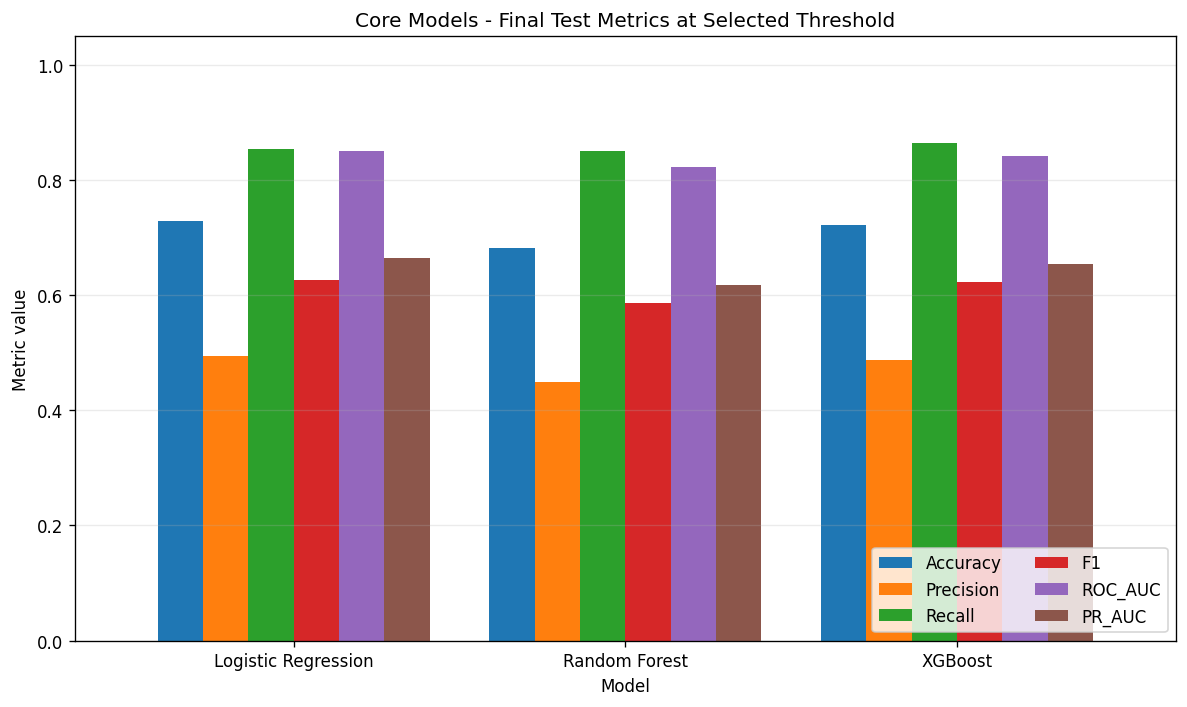

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_comparison_02_default_validation_metrics_bar.png


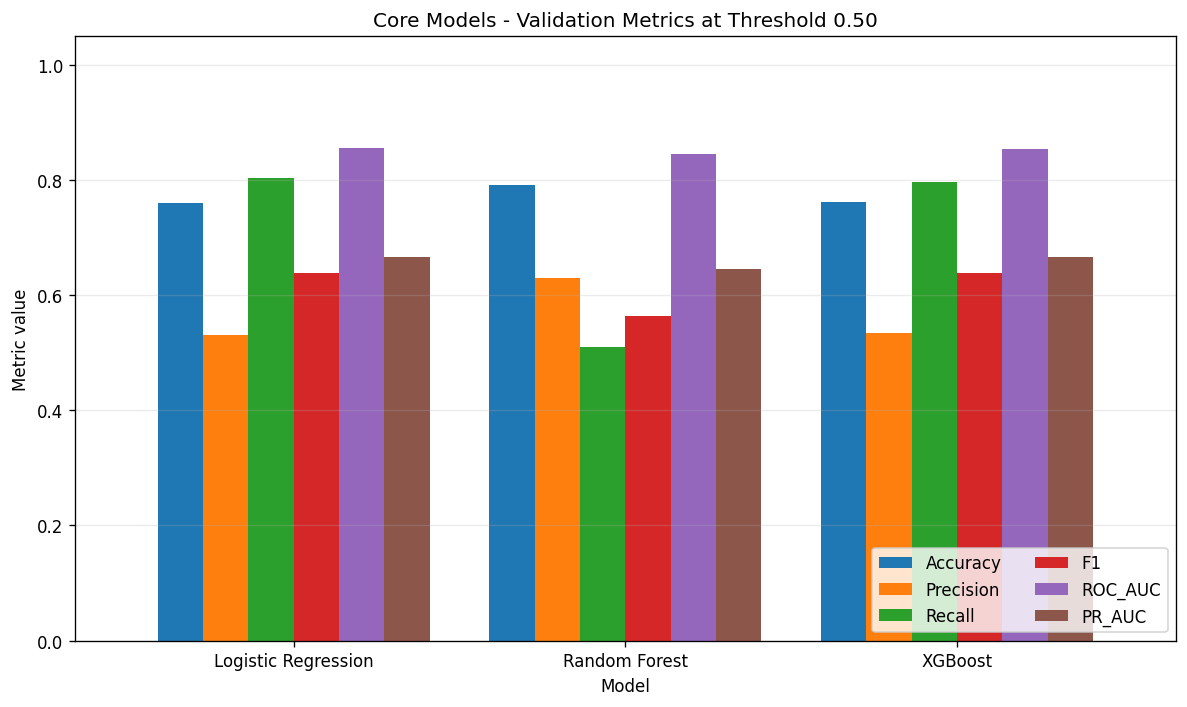

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_comparison_03_selected_validation_metrics_bar.png


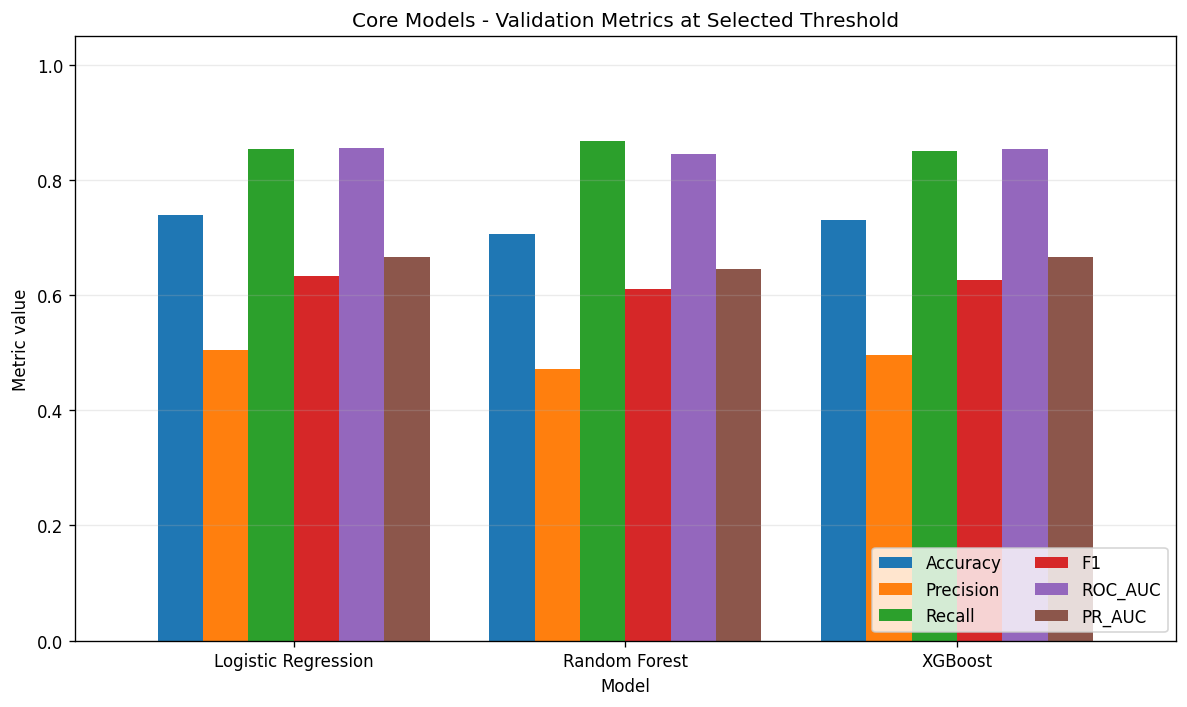

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_comparison_04_selected_thresholds.png


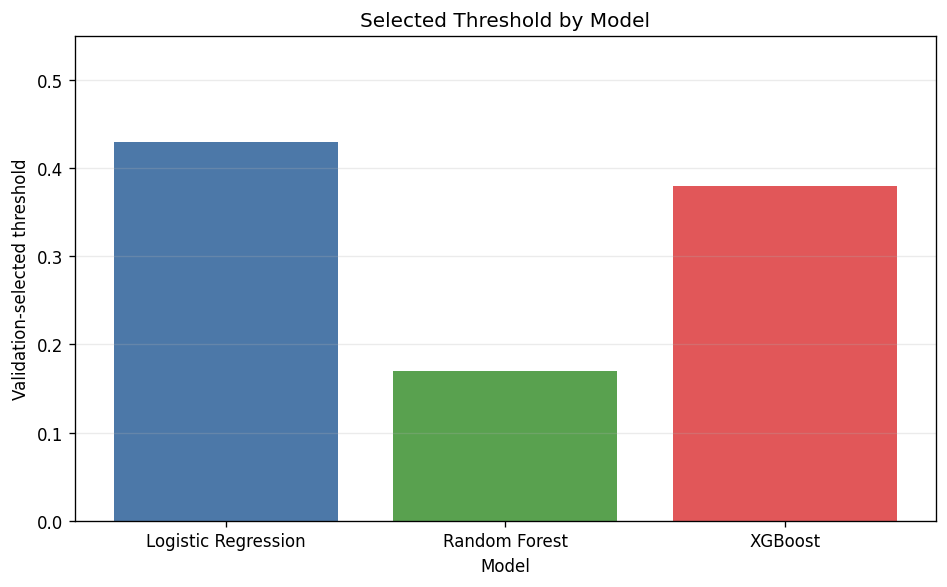

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_comparison_05_validation_vs_test_recall_f1.png


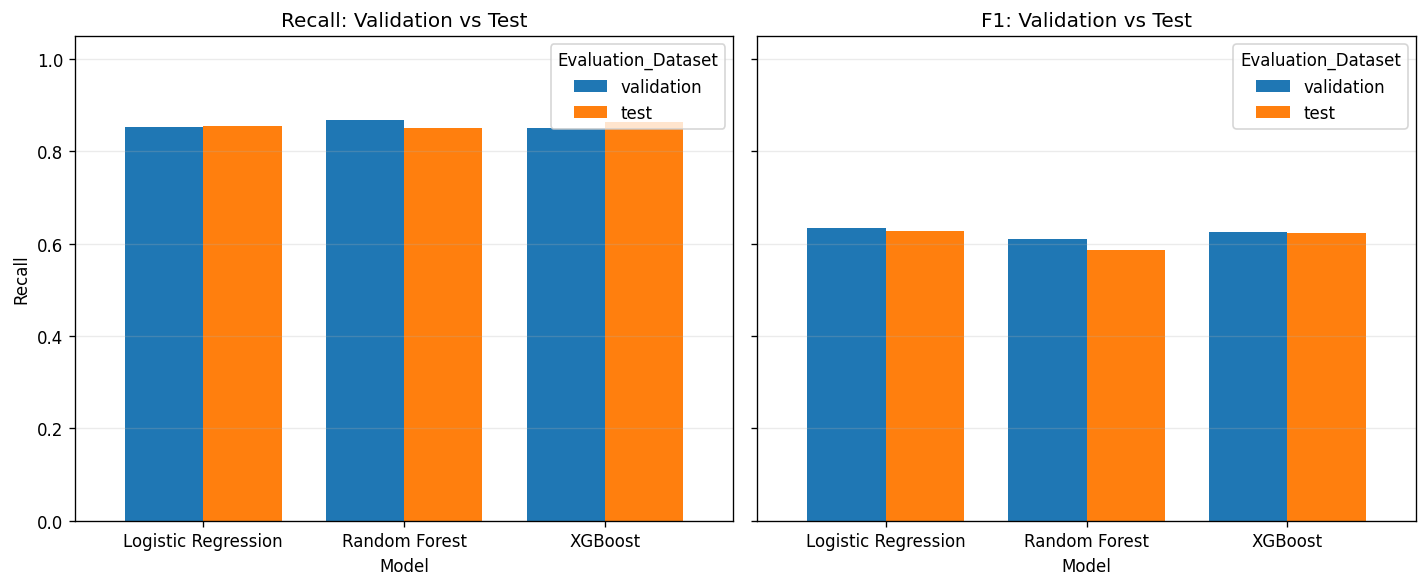

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_comparison_06_precision_recall_tradeoff_test.png


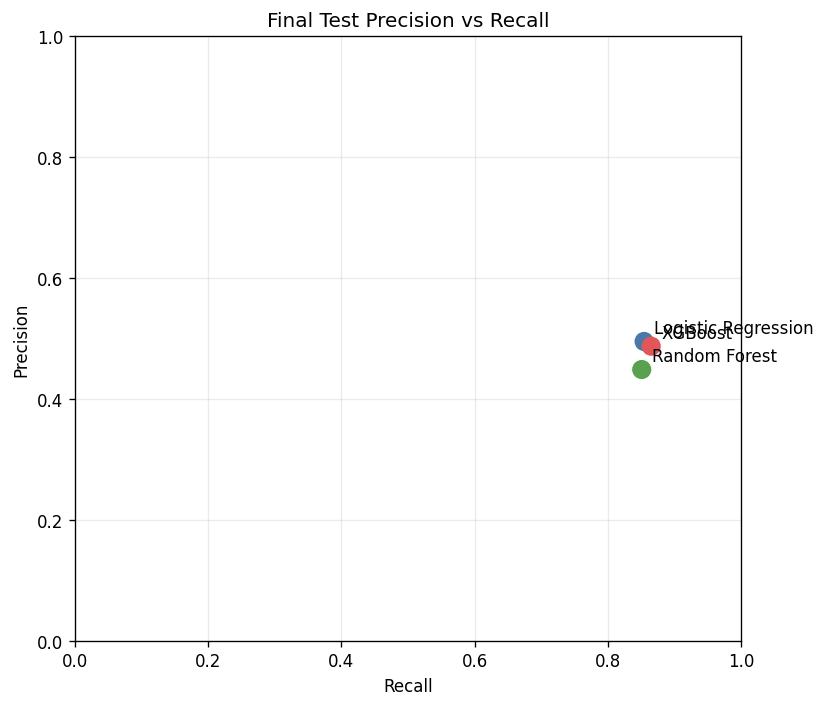

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_comparison_07_threshold_sensitivity_recall.png


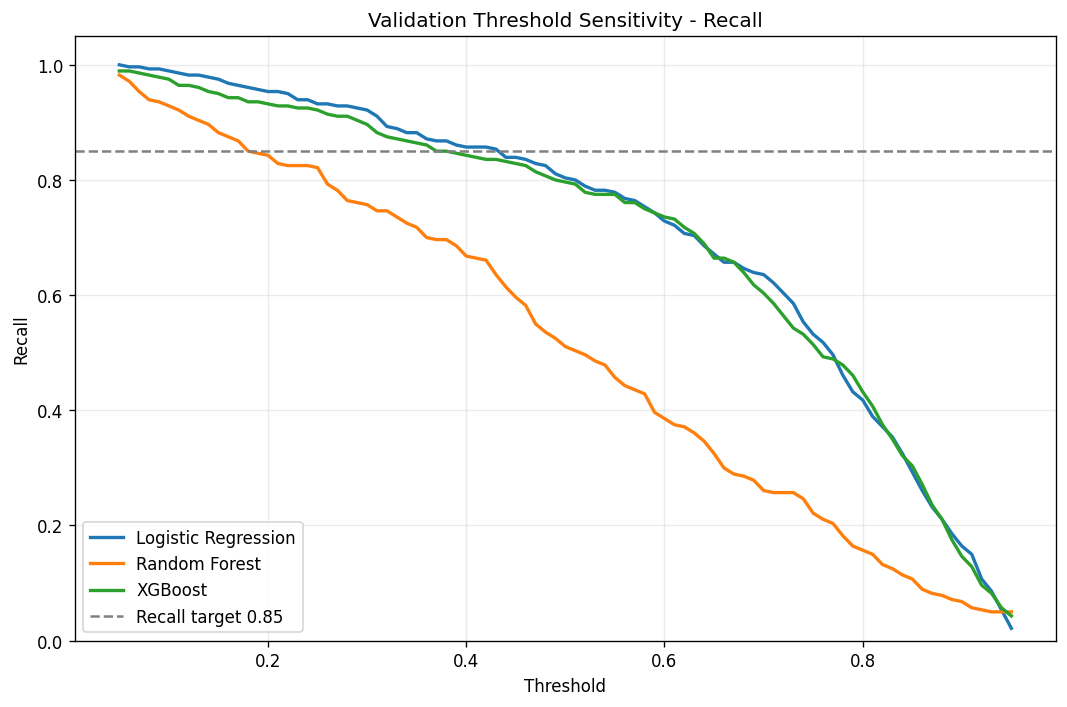

,File,Path,Created
0,model_comparison_01_selected_test_metrics_bar.png,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
1,model_comparison_02_default_validation_metrics...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
2,model_comparison_03_selected_validation_metric...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
3,model_comparison_04_selected_thresholds.png,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
4,model_comparison_05_validation_vs_test_recall_...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
5,model_comparison_06_precision_recall_tradeoff_...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
6,model_comparison_07_threshold_sensitivity_reca...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True


In [14]:
plot_grouped_metrics(selected_test_comparison, 'Core Models - Final Test Metrics at Selected Threshold')
save_current_figure('model_comparison_01_selected_test_metrics_bar.png')

plot_grouped_metrics(default_validation_comparison, 'Core Models - Validation Metrics at Threshold 0.50')
save_current_figure('model_comparison_02_default_validation_metrics_bar.png')

plot_grouped_metrics(selected_validation_comparison, 'Core Models - Validation Metrics at Selected Threshold')
save_current_figure('model_comparison_03_selected_validation_metrics_bar.png')

threshold_plot_df = selected_validation_comparison.set_index('Model').loc[MODEL_ORDER]
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(threshold_plot_df.index.astype(str), threshold_plot_df['Threshold'], color=['#4C78A8', '#59A14F', '#E15759'])
ax.set_title('Selected Threshold by Model')
ax.set_xlabel('Model')
ax.set_ylabel('Validation-selected threshold')
ax.set_ylim(0, max(0.55, threshold_plot_df['Threshold'].max() + 0.1))
ax.grid(axis='y', alpha=0.25)
save_current_figure('model_comparison_04_selected_thresholds.png')

generalization_df = pd.concat([
    selected_validation_comparison.assign(Evaluation_Dataset='validation'),
    selected_test_comparison.assign(Evaluation_Dataset='test'),
], ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, metric in zip(axes, ['Recall', 'F1']):
    pivot = generalization_df.pivot(index='Model', columns='Evaluation_Dataset', values=metric).loc[MODEL_ORDER]
    pivot[['validation', 'test']].plot(kind='bar', ax=ax, width=0.78)
    ax.set_title(f'{metric}: Validation vs Test')
    ax.set_xlabel('Model')
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=0.25)
    ax.tick_params(axis='x', rotation=0)
save_current_figure('model_comparison_05_validation_vs_test_recall_f1.png')

fig, ax = plt.subplots(figsize=(7, 6))
scatter_df = selected_test_comparison.set_index('Model').loc[MODEL_ORDER].reset_index()
ax.scatter(scatter_df['Recall'], scatter_df['Precision'], s=110, color=['#4C78A8', '#59A14F', '#E15759'])
for _, row in scatter_df.iterrows():
    ax.annotate(row['Model'], (row['Recall'], row['Precision']), xytext=(6, 5), textcoords='offset points')
ax.set_title('Final Test Precision vs Recall')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
save_current_figure('model_comparison_06_precision_recall_tradeoff_test.png')

fig, ax = plt.subplots(figsize=(9, 6))
for model_name in MODEL_ORDER:
    curve_df = threshold_sensitivity_combined[threshold_sensitivity_combined['Model'].astype(str) == model_name]
    ax.plot(curve_df['Threshold'], curve_df['Recall'], linewidth=2, label=model_name)
ax.axhline(RECALL_TARGET, color='gray', linestyle='--', linewidth=1.5, label=f'Recall target {RECALL_TARGET:.2f}')
ax.set_title('Validation Threshold Sensitivity - Recall')
ax.set_xlabel('Threshold')
ax.set_ylabel('Recall')
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend(loc='best')
save_current_figure('model_comparison_07_threshold_sensitivity_recall.png')

expected_figures = [
    'model_comparison_01_selected_test_metrics_bar.png',
    'model_comparison_02_default_validation_metrics_bar.png',
    'model_comparison_03_selected_validation_metrics_bar.png',
    'model_comparison_04_selected_thresholds.png',
    'model_comparison_05_validation_vs_test_recall_f1.png',
    'model_comparison_06_precision_recall_tradeoff_test.png',
    'model_comparison_07_threshold_sensitivity_recall.png',
]
figure_output_check = pd.DataFrame([
    {'File': filename, 'Path': FIGURES_DIR / filename, 'Created': (FIGURES_DIR / filename).exists()}
    for filename in expected_figures
])
display(figure_output_check)
if not figure_output_check['Created'].all():
    missing = figure_output_check.loc[~figure_output_check['Created'], 'File'].tolist()
    raise FileNotFoundError(f'Missing comparison figures: {missing}')

## 15. Final Interpretation Summary

In [15]:
balanced_model = best_model_summary.loc[
    best_model_summary['Criterion'] == 'Recommended_Balanced_Model', 'Model'
].iloc[0]
recall_model = best_model_summary.loc[
    best_model_summary['Criterion'] == 'Recommended_Recall_Focused_Model', 'Model'
].iloc[0]
best_recall_model = best_model_summary.loc[best_model_summary['Criterion'] == 'Best model by Recall', 'Model'].iloc[0]
best_f1_model = best_model_summary.loc[best_model_summary['Criterion'] == 'Best model by F1', 'Model'].iloc[0]
best_roc_model = best_model_summary.loc[best_model_summary['Criterion'] == 'Best model by ROC_AUC', 'Model'].iloc[0]
best_pr_model = best_model_summary.loc[best_model_summary['Criterion'] == 'Best model by PR_AUC', 'Model'].iloc[0]

interpretation_summary = pd.DataFrame([
    {'Item': 'Best recall model', 'Value': best_recall_model},
    {'Item': 'Best F1 model', 'Value': best_f1_model},
    {'Item': 'Best ROC_AUC model', 'Value': best_roc_model},
    {'Item': 'Best PR_AUC model', 'Value': best_pr_model},
    {'Item': 'Recommended balanced model', 'Value': balanced_model},
    {'Item': 'Recommended recall-focused model', 'Value': recall_model},
])
display(interpretation_summary)

print('Interpretation summary:')
print(f'- Best recall model: {best_recall_model}')
print(f'- Best F1 model: {best_f1_model}')
print(f'- Best ROC_AUC model: {best_roc_model}')
print(f'- Best PR_AUC model: {best_pr_model}')
print(f'- Recommended balanced model: {balanced_model}')
print(f'- Recommended recall-focused model: {recall_model}')
print('Recommendation logic uses final selected-threshold test metrics and does not choose by recall alone.')

,Item,Value
0,Best recall model,XGBoost
1,Best F1 model,Logistic Regression
2,Best ROC_AUC model,Logistic Regression
3,Best PR_AUC model,Logistic Regression
4,Recommended balanced model,Logistic Regression
5,Recommended recall-focused model,XGBoost


Interpretation summary:
- Best recall model: XGBoost
- Best F1 model: Logistic Regression
- Best ROC_AUC model: Logistic Regression
- Best PR_AUC model: Logistic Regression
- Recommended balanced model: Logistic Regression
- Recommended recall-focused model: XGBoost
Recommendation logic uses final selected-threshold test metrics and does not choose by recall alone.


## 16. Runtime and Source Safety Confirmation

In [16]:
print('Notebook 05 Model Comparison summary')
print(f'Models compared: {MODEL_ORDER}')
print(f'Input source folder: {DATA_REPORTS_DIR}')
print(f'Comparison CSV output folder: {DATA_REPORTS_DIR}')
print(f'Comparison figure output folder: {FIGURES_DIR}')
print('No model training is performed.')
print('No preprocessing orchestration is called.')
print('No threshold retuning or prediction/probability generation is performed.')
print('No legacy artifacts or model pickle files are loaded.')

Notebook 05 Model Comparison summary
Models compared: ['Logistic Regression', 'Random Forest', 'XGBoost']
Input source folder: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports
Comparison CSV output folder: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports
Comparison figure output folder: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures
No model training is performed.
No preprocessing orchestration is called.
No threshold retuning or prediction/probability generation is performed.
No legacy artifacts or model pickle files are loaded.
